# Módulo 3 · Muchos patrones de disparo con cuatro números (Izhikevich)

Las neuronas registradas en una rebanada se clasifican por cómo disparan: regular, en ráfagas, rápido, con adaptación. Izhikevich (2003) mostró que dos ecuaciones reproducen la mayoría de estos patrones:

$$\frac{dv}{dt}=0.04v^2+5v+140-u+I,\qquad \frac{du}{dt}=a(bv-u),\qquad v\ge30 \Rightarrow v\leftarrow c,\ u\leftarrow u+d$$

$u$ es una corriente lenta de recuperación; $a$ fija su velocidad, $b$ su acoplamiento con $v$, $c$ el voltaje de reinicio y $d$ el impulso después de cada disparo.

In [1]:
import sys, inspect
sys.path.insert(0, '..')            # make the neurosim package importable
import numpy as np
import matplotlib.pyplot as plt
import neurosim as ns
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

In [2]:
print(inspect.getsource(ns.izhikevich_cell))

def izhikevich_cell(a, b, c, d, stimulus, duration=300.0, dt=0.1):
    """Single-cell, scalar version of the Izhikevich model: the clearest
    form for reading the equations (and the fastest for one cell)."""
    drive = stimulus if callable(stimulus) else (lambda _t: stimulus)
    n_steps = int(round(duration / dt))
    t = np.arange(n_steps) * dt
    v_trace = np.empty(n_steps)
    v, u = -65.0, b * -65.0
    spikes = []
    for i in range(n_steps):
        if v >= 30.0:                       # spike: record, then reset
            v_trace[i] = 30.0
            spikes.append(t[i])
            v, u = c, u + d
        else:
            v_trace[i] = v
        dv = 0.04 * v * v + 5.0 * v + 140.0 - u + drive(t[i])
        du = a * (b * v - u)
        v, u = v + dt * dv, u + dt * du
    return {"t": t, "v": v_trace, "spikes": np.asarray(spikes)}



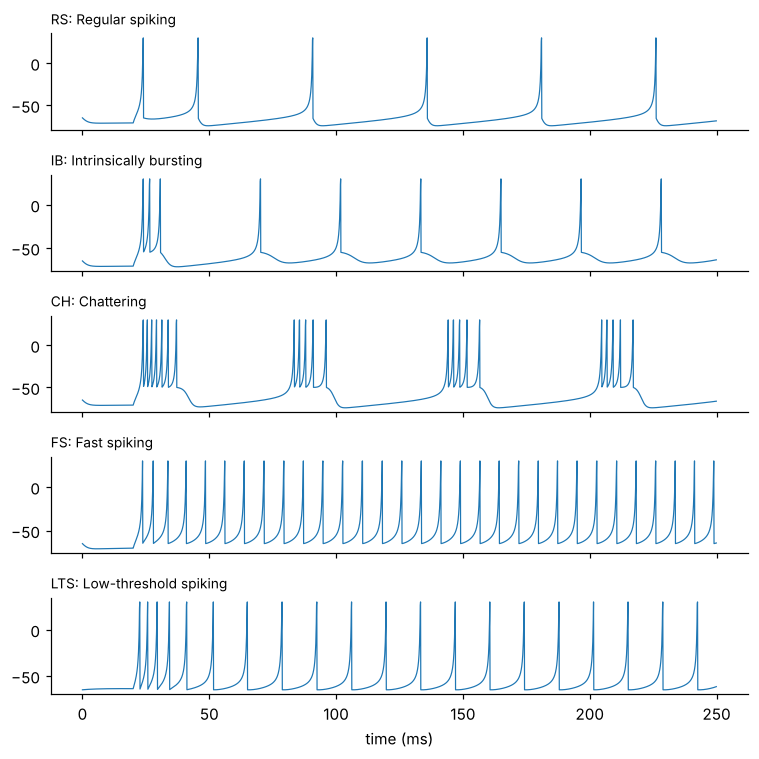

In [3]:
fig, ax = plt.subplots(5, 1, figsize=(7, 7), sharex=True)
for a_, (key, spec) in zip(ax, ns.IZH_CLASSES.items()):
    r = ns.izhikevich_cell(*spec['abcd'], lambda t: 10.0 * (t >= 20), duration=250)
    a_.plot(r['t'], r['v'], lw=0.8); a_.set_title(f"{key}: {spec['name']}", loc='left', fontsize=9)
ax[-1].set_xlabel('time (ms)'); plt.tight_layout(); plt.show()

## Ejercicios
1. Mueve `c` de -65 a -50 en pasos de 5 con los valores de RS. ¿Con qué valor la célula empieza a disparar en ráfagas?
2. Aumenta `d` en la célula FS. ¿Cuándo aparece la adaptación?
3. Ejecuta con `dt=1.0`. ¿Qué patrones se mantienen?
4. Busca en Izhikevich (2003) los parámetros *tálamo-cortical* y *resonador* y agrégalos.